# Naive Bayes Spam Classification Pipeline

This notebook demonstrates an end-to-end Machine Learning workflow using **Multinomial Naive Bayes** for NLP text classification (Spam vs. Ham).

### Pipeline Overview:
1. **Data Ingestion:** Load labeled dataset from `csv/spam_dataset.csv`.
2. **Exploratory Data Analysis (EDA):** Class distribution and text inspection.
3. **Feature Extraction:** Convert raw text into numerical feature matrices using `CountVectorizer`.
4. **Model Training:** Train a `MultinomialNB` classifier.
5. **Evaluation:** Confusion matrix, accuracy score, precision, recall, and F1-score.
6. **Inference:** Test custom real-world messages.

In [11]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.pipeline import Pipeline

print("Libraries successfully imported!")

Libraries successfully imported!


## 1. Load Dataset from CSV

In [12]:
# Find dataset path relative to root or current dir
csv_path = os.path.join("..", "..", "csv", "spam_dataset.csv")
if not os.path.exists(csv_path):
    csv_path = os.path.join("csv", "spam_dataset.csv")

df = pd.read_csv(csv_path)
print(f"Dataset Shape: {df.shape}")
print("\nClass Distribution:")
print(df['label'].value_counts())
df.head()

Dataset Shape: (120, 2)

Class Distribution:
label
ham     60
spam    60
Name: count, dtype: int64


,label,message
0,ham,"Hey, are you free for lunch today around 1 PM?"
1,ham,Can you please send me the project report when...
2,ham,The team meeting has been rescheduled to 3 PM ...
3,ham,Happy birthday! Hope you have a wonderful year...
4,ham,Did you finish the assignment for tomorrow class?


## 2. Train-Test Split & Pipeline Setup

In [13]:
X = df['message']
y = df['label']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# Create Scikit-learn Pipeline
pipeline = Pipeline([
    ('vectorizer', CountVectorizer(lowercase=True)),
    ('classifier', MultinomialNB(alpha=0.1))
])

# Fit model
pipeline.fit(X_train, y_train)
print("Pipeline training complete!")

Pipeline training complete!


## 3. Model Evaluation

Test Set Accuracy: 95.83%

Classification Report:
              precision    recall  f1-score   support

         ham       1.00      0.92      0.96        12
        spam       0.92      1.00      0.96        12

    accuracy                           0.96        24
   macro avg       0.96      0.96      0.96        24
weighted avg       0.96      0.96      0.96        24



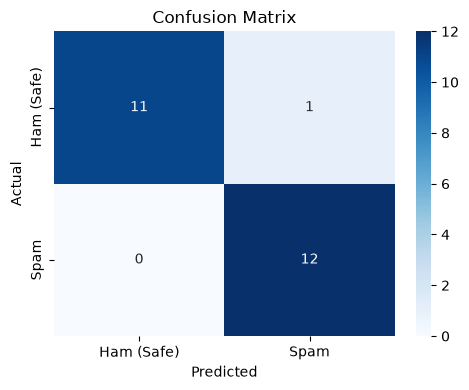

In [14]:
y_pred = pipeline.predict(X_test)
acc = accuracy_score(y_test, y_pred)
print(f"Test Set Accuracy: {acc * 100:.2f}%")
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

# Confusion Matrix Plot
cm = confusion_matrix(y_test, y_pred, labels=['ham', 'spam'])
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=['Ham (Safe)', 'Spam'], 
            yticklabels=['Ham (Safe)', 'Spam'])
plt.title('Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.tight_layout()
plt.show()

## 4. Live Message Prediction

In [15]:
def classify_message(text: str):
    prediction = pipeline.predict([text])[0]
    probs = pipeline.predict_proba([text])[0]
    classes = pipeline.classes_
    prob_map = {c: f"{p*100:.1f}%" for c, p in zip(classes, probs)}
    
    status = "[ SPAM DETECTED ]" if prediction == "spam" else "[ LEGITIMATE / HAM ]"
    print(f"Text       : {text}")
    print(f"Prediction : {status}")
    print(f"Confidence : {prob_map}\n")

# Test examples
classify_message("Hey, are you free for lunch tomorrow around 2 PM?")
classify_message("Congratulations! You won a $1000 cash lottery prize. Click link to claim now!")
classify_message("URGENT: Your debit card was blocked due to suspicious activity. Verify credentials.")
classify_message("Please send over the updated code repository link when ready.")

Text       : Hey, are you free for lunch tomorrow around 2 PM?
Prediction : [ LEGITIMATE / HAM ]
Confidence : {np.str_('ham'): '100.0%', np.str_('spam'): '0.0%'}

Text       : Congratulations! You won a $1000 cash lottery prize. Click link to claim now!
Prediction : [ SPAM DETECTED ]
Confidence : {np.str_('ham'): '0.0%', np.str_('spam'): '100.0%'}

Text       : URGENT: Your debit card was blocked due to suspicious activity. Verify credentials.
Prediction : [ SPAM DETECTED ]
Confidence : {np.str_('ham'): '0.0%', np.str_('spam'): '100.0%'}

Text       : Please send over the updated code repository link when ready.
Prediction : [ LEGITIMATE / HAM ]
Confidence : {np.str_('ham'): '100.0%', np.str_('spam'): '0.0%'}

